<a href="https://colab.research.google.com/github/sachinthadilshann/pytorch_course_by_DanielBourke/blob/main/07_pytorch_experiment_tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
from torch import nn
from torchvision import transforms

try:
  from torchinfo import summary
except:
    print("[INFO] Couldn't find torchinfo... installing it.")
    !pip install -q torchinfo
    from torchinfo import summary

try:
    from going_modular.going_modular import data_setup, engine

except:

    print("[INFO] Couldn't find going_modular scripts... downloading them from GitHub.")
    !git clone https://github.com/sachinthadilshann/pytorch_course_by_DanielBourke/
    !mv pytorch_course_by_DanielBourke/going_modular .
    !rm -rf pytorch_course_by_DanielBourke
    from going_modular.going_modular import data_setup, engine

[INFO] Couldn't find torchinfo... installing it.
[INFO] Couldn't find going_modular scripts... downloading them from GitHub.
Cloning into 'pytorch_course_by_DanielBourke'...
remote: Enumerating objects: 148, done.
remote: Counting objects: 100% (148/148), done.
remote: Compressing objects: 100% (139/139), done.
remote: Total 148 (delta 72), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (148/148), 20.35 MiB | 14.18 MiB/s, done.
Resolving deltas: 100% (72/72), done.


In [2]:
import os
import zipfile

from pathlib import Path

import requests

def download_data(source:str,
                  destination:str,
                  remove_source:bool=True) -> Path:

    data_path = Path("data/")

    image_path = data_path/ destination

    if image_path.is_dir():
      print(f"[INFO] {image_path} directory exists, skipping download.")
    else:
      print(f"[INFO] Did not find {image_path} directory, creating one...")
      image_path.mkdir(parents=True, exist_ok=True)
      target_file = Path(source).name
      with open(data_path / target_file, "wb") as f:
          print(f"[INFO] Downloading {target_file} from {source}...")
          request = requests.get(source)
          f.write(request.content)

      with zipfile.ZipFile(data_path / target_file, "r") as zip_ref:
          print(f"[INFO] Unzipping {target_file} data...")
          zip_ref.extractall(image_path)

      if remove_source:
          os.remove(data_path / target_file)

    return image_path

image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] Did not find data/pizza_steak_sushi directory, creating one...
[INFO] Downloading pizza_steak_sushi.zip from https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip...
[INFO] Unzipping pizza_steak_sushi.zip data...


PosixPath('data/pizza_steak_sushi')

## Create Datasets and Dataloders


In [3]:
train_dir = image_path / "train"
test_dir = image_path / "test"

device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])

from torchvision import transforms

manual_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize
])

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    transform=manual_transforms,
    batch_size=32
)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x78ff49339e80>,
 ['pizza', 'steak', 'sushi'])

In [5]:

train_dir =  image_path / "train"
test_dir = image_path / "test"

device = "cuda" if torch.cuda.is_available() else "cpu"

import torchvision

weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
auto_transforms = weights.transforms()

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                              test_dir=test_dir,
                                                                              transform=auto_transforms,
                                                                              batch_size=32)

train_dataloader, test_dataloader, class_names



(<torch.utils.data.dataloader.DataLoader at 0x78ff49382990>,
 ['pizza', 'steak', 'sushi'])

## Getting pretrained model

In [6]:
model = torchvision.models.efficientnet_b0(weights=weights).to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 170MB/s]


In [7]:
for param in model.features.parameters():
  param.requires_grad = False # Freeze all base layers



model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280,
              out_features=len(class_names),
              bias=True)).to(device)


In [8]:
from torchinfo import summary

summary(model=model,
                input_size=(32, 3, 224, 224),
                col_names=["input_size", "output_size", "num_params", "trainable"],
                col_width=20)

Layer (type:depth-idx)                                  Input Shape          Output Shape         Param #              Trainable
EfficientNet                                            [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential: 1-1                                       [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation: 2-1                        [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d: 3-1                                 [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d: 3-2                            [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU: 3-3                                   [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential: 2-2                                  [32, 32, 112, 112]   [32, 16, 112, 112]   --                   Fal

## Train a single model and track result

In [9]:
loss_fn =  nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)



In [10]:
#setup summarywriter

from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter()

In [11]:
writer

In [12]:
from typing import Dict,List,Tuple
from tqdm.auto import tqdm

from going_modular.going_modular.engine import train_step, test_step


def train(model:torch.nn.Module,
          train_dataloader:torch.utils.data.DataLoader,
          test_dataloader:torch.utils.data.DataLoader,
          optimizer:torch.optim.Optimizer,
          loss_fn: torch.nn.Module,
          epochs:int,
          device:torch.device) -> Dict[str, List[float]]:

    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []
    }




    for epoch in tqdm(range(epochs)):
      train_loss, train_acc = train_step(model=model,
                                          dataloader=train_dataloader,
                                          loss_fn=loss_fn,
                                          optimizer=optimizer,
                                          device=device)
      test_loss, test_acc = test_step(model=model,
                                      dataloader=test_dataloader,
                                      loss_fn=loss_fn,
                                      device=device)
      print(
          f"Epoch: {epoch+1} | "
          f"train_loss: {train_loss:.4f} | "
          f"train_acc: {train_acc:.4f} | "
          f"test_loss: {test_loss:.4f} | "
          f"test_acc: {test_acc:.4f}"
      )


      results["train_loss"].append(train_loss)
      results["train_acc"].append(train_acc)
      results["test_loss"].append(test_loss)
      results["test_acc"].append(test_acc)

      #track loss and accuracy
      writer.add_scalars(main_tag="Loss",
                         tag_scalar_dict={"train_loss": train_loss,
                                          "test_loss": test_loss},
                         global_step=epoch)

      writer.add_scalars(main_tag="Accuracy",
                         tag_scalar_dict={"train_acc": train_acc,
                                          "test_acc": test_acc},
                         global_step=epoch)
      writer.add_graph(model=model,
                       input_to_model=torch.rand(32, 3, 224, 224).to(device))
    writer.close()
    return results

In [13]:
results =  train(model=model,
                 train_dataloader=train_dataloader,
                 test_dataloader=test_dataloader,
                 optimizer=optimizer,
                 loss_fn=loss_fn,
                 epochs=5,
                 device=device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0545 | train_acc: 0.3750 | test_loss: 0.8758 | test_acc: 0.7330
Epoch: 2 | train_loss: 0.8610 | train_acc: 0.7227 | test_loss: 0.7180 | test_acc: 0.8343
Epoch: 3 | train_loss: 0.7996 | train_acc: 0.6406 | test_loss: 0.6524 | test_acc: 0.8655
Epoch: 4 | train_loss: 0.6408 | train_acc: 0.9141 | test_loss: 0.6775 | test_acc: 0.8248
Epoch: 5 | train_loss: 0.6897 | train_acc: 0.7305 | test_loss: 0.6693 | test_acc: 0.8040


In [14]:
#results

In [15]:
def create_writer(experiment_name:str,
                  model_name:str,
                  extra:str =None):

  from datetime import datetime
  import os


  timestamp = datetime.now()

  timestamp = timestamp.strftime("%d_%m_%Y_%H_%M_%S")


  if extra :
    log_dir = os.path.join("runs",timestamp,experiment_name,model_name,extra)

  else:

    log_dir = os.path.join("runs",timesstamp,experiment_name,model_name)

  print(f"[INFO] Created SummaryWriter saving to {log_dir}")

  return SummaryWriter(log_dir=log_dir)



In [16]:
example_writer = create_writer(experiment_name="data_10_percent",
                               model_name="effnetB0",
                               extra="5_epochs")

[INFO] Created SummaryWriter saving to runs/31_10_2026_04_32_54/data_10_percent/effnetB0/5_epochs


In [17]:
from tqdm.auto import tqdm
from timeit import default_timer as timer


def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn:torch.nn.Module,
          epochs:int,
          device: torch.device,
          writer: torch.utils.tensorboard.writer.SummaryWriter) -> Dict[str, List[float]]:

  results = {"train_loss": [],
             "train_acc": [],
             "test_loss": [],
             "test_acc": []
  }

  for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                          dataloader=train_dataloader,
                                          loss_fn=loss_fn,
                                          optimizer=optimizer,
                                          device=device)
        test_loss, test_acc = test_step(model=model,
          dataloader=test_dataloader,
          loss_fn=loss_fn,
          device=device)


        print(
          f"Epoch: {epoch+1} | "
          f"train_loss: {train_loss:.4f} | "
          f"train_acc: {train_acc:.4f} | "
          f"test_loss: {test_loss:.4f} | "
          f"test_acc: {test_acc:.4f}"
        )

        # Update results dictionary
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

        if writer:
            # Add results to SummaryWriter
            writer.add_scalars(main_tag="Loss",
                               tag_scalar_dict={"train_loss": train_loss,
                                                "test_loss": test_loss},
                               global_step=epoch)
            writer.add_scalars(main_tag="Accuracy",
                               tag_scalar_dict={"train_acc": train_acc,
                                                "test_acc": test_acc},
                               global_step=epoch)

            writer.close()
        else:
            pass

In [18]:
data_10_percent_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                                     destination="pizza_steak_sushi")

data_20_percent_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip",
                                     destination="pizza_steak_sushi_20_percent")

[INFO] data/pizza_steak_sushi directory exists, skipping download.
[INFO] Did not find data/pizza_steak_sushi_20_percent directory, creating one...
[INFO] Downloading pizza_steak_sushi_20_percent.zip from https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip...
[INFO] Unzipping pizza_steak_sushi_20_percent.zip data...


In [19]:
train_dir_10_percent = data_10_percent_path / "train"
train_dir_20_percent = data_20_percent_path / "train"


test_dir = data_10_percent_path / "test"


print(f"Training directory 10%: {train_dir_10_percent}")
print(f"Training directory 20%: {train_dir_20_percent}")
print(f"Testing directory: {test_dir}")

Training directory 10%: data/pizza_steak_sushi/train
Training directory 20%: data/pizza_steak_sushi_20_percent/train
Testing directory: data/pizza_steak_sushi/test


In [20]:
from torchvision import transforms

normilize = transforms.Normalize(mean=[0.485,0.456,0.406],
                                std=[0.229,0.224,0.225])

simple_transforms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    normilize
])

In [21]:
BATCH_SIZE = 32

train_dataloader_10_percent,test_dataloader,class_names = data_setup.create_dataloaders(train_dir=train_dir_10_percent,
                                                                                        test_dir=test_dir,
                                                                                        transform=simple_transforms,
                                                                                        batch_size = BATCH_SIZE
                                                                                        )

train_dataloader_20_percent,test_dataloader,class_names = data_setup.create_dataloaders(train_dir=train_dir_20_percent,
                                                                                        test_dir=test_dir,
                                                                                        transform=simple_transforms,
                                                                                        batch_size = BATCH_SIZE
                                                                                        )

In [22]:
import torch
from torchinfo import summary


effnetb2_weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT

effnetb2 = torchvision.models.efficientnet_b2(weights=effnetb2_weights).to(device)

print(f"Number of in_features to final layer of EfficientNetB2: {len(effnetb2.classifier.state_dict()['1.weight'][0])}")


Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 94.3MB/s]


Number of in_features to final layer of EfficientNetB2: 1408


In [23]:
import torchvision
import torch
from torch import nn


OUT_FEATURES = len(class_names)

def create_effnetb0():
  weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
  model = torchvision.models.efficientnet_b0(weights=weights).to(device)

  for param in model.features.parameters():
    param.requires_grad = False

  model.classifier = nn.Sequential(
      nn.Dropout(p=0.2, inplace=True),
      nn.Linear(in_features=1280,
                out_features=OUT_FEATURES,
                bias=True)
  ).to(device)

  model.name = "effnetb0"
  print(f"[INFO] Created {model.name} model.")

  return model

def create_effnetb2():
  weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT
  model = torchvision.models.efficientnet_b2(weights=weights).to(device)

  for param in model.features.parameters():
    param.requires_grad = False

  model.classifier = nn.Sequential(
      nn.Dropout(p=0.2, inplace=True),
      nn.Linear(in_features=1408,
                out_features=OUT_FEATURES,
                bias=True))

  model.name = "effnetb2"
  print(f"[INFO] Created {model.name} model.")

  return model



In [24]:
effnetb0 = create_effnetb0()
effnetb2 = create_effnetb2()

[INFO] Created effnetb0 model.
[INFO] Created effnetb2 model.


In [25]:



num_epochs = [5,10]

models = ['effnetb0','effnetb2']

train_dataloaders = {"data_10_percent": train_dataloader_10_percent,"data_20_percent": train_dataloader_20_percent}

In [26]:
from going_modular.going_modular.utils import save_model

experiment_number = 0

for dataloader_name, train_dataloader in train_dataloaders.items():
  for epochs in num_epochs:
    for model_name in models:
      experiment_number += 1
      print(f"[INFO] Experiment number: {experiment_number}")
      print(f"[INFO] Model: {model_name}")
      print(f"[INFO] DataLoader: {dataloader_name}")
      print(f"[INFO] Number of epochs: {epochs}")

      if model_name == "effnetb0":
        model = create_effnetb0()
      else:
        model = create_effnetb2()


      model.to(device)

      loss_fn = nn.CrossEntropyLoss()
      optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

      train(model=model,
            train_dataloader = train_dataloader,
            test_dataloader = test_dataloader,
            optimizer = optimizer,
            loss_fn=loss_fn,
            epochs=epochs,
            device=device,
            writer = create_writer(experiment_name=dataloader_name,
                                   model_name=model_name,
                                   extra=f"{epochs}_epochs"))

      save_filepath = f"07_{model_name}_{dataloader_name}_{epochs}_epochs.pth"
      save_model(model=model,
                 target_dir="models",
                 model_name=save_filepath)
      print("-"*50 + "\n")

[INFO] Experiment number: 1
[INFO] Model: effnetb0
[INFO] DataLoader: data_10_percent
[INFO] Number of epochs: 5
[INFO] Created effnetb0 model.
[INFO] Created SummaryWriter saving to runs/31_10_2026_04_32_58/data_10_percent/effnetb0/5_epochs


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1184 | train_acc: 0.3203 | test_loss: 0.9586 | test_acc: 0.5805
Epoch: 2 | train_loss: 0.8990 | train_acc: 0.6719 | test_loss: 0.9072 | test_acc: 0.5994
Epoch: 3 | train_loss: 0.8219 | train_acc: 0.6797 | test_loss: 0.8128 | test_acc: 0.5994
Epoch: 4 | train_loss: 0.7019 | train_acc: 0.8320 | test_loss: 0.6341 | test_acc: 0.8248
Epoch: 5 | train_loss: 0.7002 | train_acc: 0.7109 | test_loss: 0.5716 | test_acc: 0.8655
[INFO] Saving model to: models/07_effnetb0_data_10_percent_5_epochs.pth
--------------------------------------------------

[INFO] Experiment number: 2
[INFO] Model: effnetb2
[INFO] DataLoader: data_10_percent
[INFO] Number of epochs: 5
[INFO] Created effnetb2 model.
[INFO] Created SummaryWriter saving to runs/31_10_2026_04_33_08/data_10_percent/effnetb2/5_epochs


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0766 | train_acc: 0.4023 | test_loss: 0.9395 | test_acc: 0.7538
Epoch: 2 | train_loss: 0.8711 | train_acc: 0.6914 | test_loss: 0.8667 | test_acc: 0.7036
Epoch: 3 | train_loss: 0.7889 | train_acc: 0.7188 | test_loss: 0.7987 | test_acc: 0.7443
Epoch: 4 | train_loss: 0.7592 | train_acc: 0.7500 | test_loss: 0.6678 | test_acc: 0.8759
Epoch: 5 | train_loss: 0.6416 | train_acc: 0.7695 | test_loss: 0.6421 | test_acc: 0.9384
[INFO] Saving model to: models/07_effnetb2_data_10_percent_5_epochs.pth
--------------------------------------------------

[INFO] Experiment number: 3
[INFO] Model: effnetb0
[INFO] DataLoader: data_10_percent
[INFO] Number of epochs: 10
[INFO] Created effnetb0 model.
[INFO] Created SummaryWriter saving to runs/31_10_2026_04_33_19/data_10_percent/effnetb0/10_epochs


  0%|          | 0/10 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.9486 | train_acc: 0.5958 | test_loss: 0.6936 | test_acc: 0.8665
Epoch: 2 | train_loss: 0.6826 | train_acc: 0.8313 | test_loss: 0.5796 | test_acc: 0.8769
Epoch: 3 | train_loss: 0.5334 | train_acc: 0.8688 | test_loss: 0.4732 | test_acc: 0.8977
Epoch: 4 | train_loss: 0.4616 | train_acc: 0.8667 | test_loss: 0.4205 | test_acc: 0.8873
Epoch: 5 | train_loss: 0.4447 | train_acc: 0.8938 | test_loss: 0.3682 | test_acc: 0.8873
Epoch: 6 | train_loss: 0.4166 | train_acc: 0.8875 | test_loss: 0.3636 | test_acc: 0.8873
Epoch: 7 | train_loss: 0.4285 | train_acc: 0.8417 | test_loss: 0.3483 | test_acc: 0.8977
Epoch: 8 | train_loss: 0.3470 | train_acc: 0.9271 | test_loss: 0.2908 | test_acc: 0.9176
Epoch: 9 | train_loss: 0.3263 | train_acc: 0.9208 | test_loss: 0.3109 | test_acc: 0.9489
Epoch: 10 | train_loss: 0.3595 | train_acc: 0.8875 | test_loss: 0.2770 | test_acc: 0.9384
[INFO] Saving model to: models/07_effnetb0_data_20_percent_10_epochs.pth
------------------------------------

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.9898 | train_acc: 0.5646 | test_loss: 0.8139 | test_acc: 0.7633
Epoch: 2 | train_loss: 0.7385 | train_acc: 0.7604 | test_loss: 0.6470 | test_acc: 0.8864
Epoch: 3 | train_loss: 0.5956 | train_acc: 0.8646 | test_loss: 0.5683 | test_acc: 0.8968
Epoch: 4 | train_loss: 0.5007 | train_acc: 0.8938 | test_loss: 0.5094 | test_acc: 0.9176
Epoch: 5 | train_loss: 0.4403 | train_acc: 0.8875 | test_loss: 0.4555 | test_acc: 0.9176
Epoch: 6 | train_loss: 0.4381 | train_acc: 0.8750 | test_loss: 0.4473 | test_acc: 0.9176
Epoch: 7 | train_loss: 0.3548 | train_acc: 0.9333 | test_loss: 0.4504 | test_acc: 0.8570
Epoch: 8 | train_loss: 0.3890 | train_acc: 0.8708 | test_loss: 0.3780 | test_acc: 0.9280
Epoch: 9 | train_loss: 0.3880 | train_acc: 0.8583 | test_loss: 0.3692 | test_acc: 0.9280
Epoch: 10 | train_loss: 0.4104 | train_acc: 0.8771 | test_loss: 0.4610 | test_acc: 0.8570
[INFO] Saving model to: models/07_effnetb2_data_20_percent_10_epochs.pth
------------------------------------

In [27]:
best_model_path = "models/07_effnetb0_data_10_percent_10_epochs.pth"

best_model  = create_effnetb0()

best_model.load_state_dict(torch.load(best_model_path))

[INFO] Created effnetb0 model.


<All keys matched successfully>

In [29]:
from pathlib import Path

effnetb0_model_size = Path(best_model_path).stat().st_size / (1024*1024)

print(f"[INFO] EffNetB0 model size: {effnetb0_model_size:.2f} MB")

[INFO] EffNetB0 model size: 15.60 MB


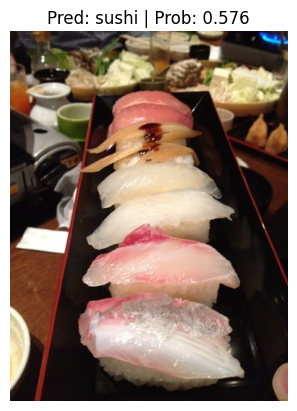

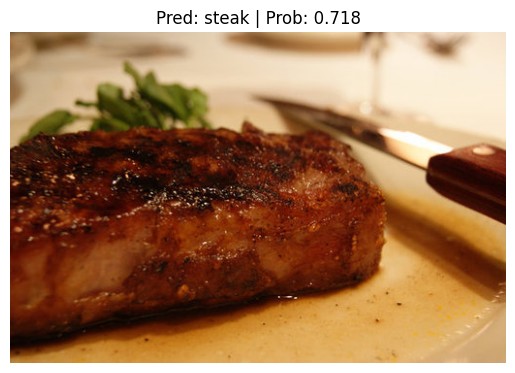

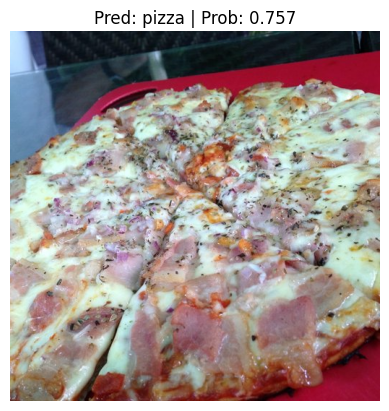

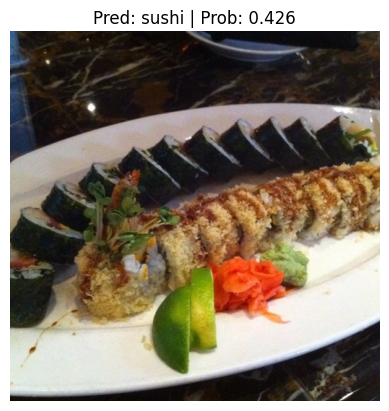

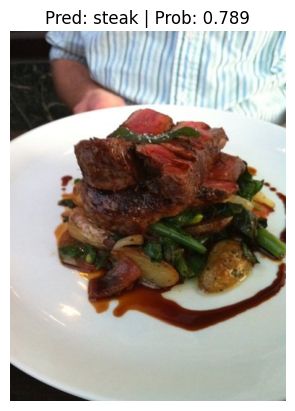

In [33]:


from going_modular.going_modular.predictions import pred_and_plot_image

import random
num_images_to_plot = 5
test_image_path_list = list(Path(data_20_percent_path / "test").glob("*/*.jpg"))
test_image_path_sample = random.sample(population=test_image_path_list,
                                       k=num_images_to_plot)


for image_path in test_image_path_sample:
    pred_and_plot_image(model=best_model,
                        image_path=image_path,
                        class_names=class_names,
                        image_size=(224, 224))

In [37]:


import requests
from pathlib import Path


custom_image_path =   Path("data/img_01.jpeg")


if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        request = requests.get("https://raw.githubusercontent.com/sachinthadilshann/pytorch_course_by_DanielBourke/refs/heads/main/img_01.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

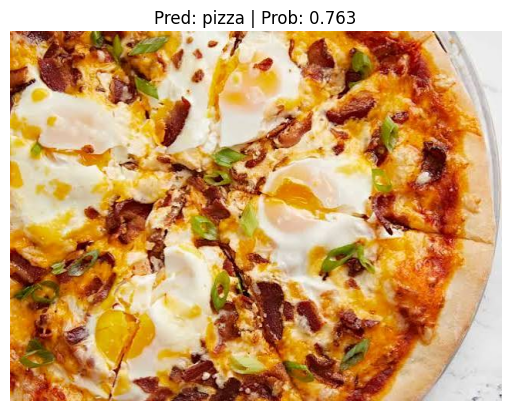

In [39]:
pred_and_plot_image(model=model,
                    image_path=custom_image_path,
                    class_names=class_names)

In [28]:
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>